In [1]:
!pip install -q torch numpy pandas matplotlib scikit-learn einops

In [2]:
import warnings
import math
import time
import random
import json
import copy

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")

In [3]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

In [4]:
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

CUDA available: True
GPU Name: Tesla T4
Device: cuda


In [5]:
from google.colab import files

uploaded = files.upload()
CSV_PATH = list(uploaded.keys())[0]
print("Using file:", CSV_PATH)

Saving Xiatang.csv to Xiatang.csv
Using file: Xiatang.csv


In [6]:
FEATURE_COLS = ["TEMP", "pH", "EC", "EUR", "COMMn", "NH3-N", "TP", "TN", "DO"]  # COMMn = CODMn (typo in raw file)
TARGET_COL = "DO"

raw_df = pd.read_csv(CSV_PATH)
raw_df["time"] = pd.to_datetime(raw_df["time"])
raw_df = raw_df.sort_values("time").drop_duplicates(subset="time").reset_index(drop=True)

print("Shape after sort/dedupe:", raw_df.shape)
raw_df.head()

Shape after sort/dedupe: (6946, 11)


,name,time,TEMP,pH,DO,EC,EUR,COMMn,NH3-N,TP,TN
0,峡塘,2020-12-17 20:00:00,1.60,7.89,13.00,385.25,23.25,1.95,0.03,0.00,1.28
1,峡塘,2020-12-18 20:00:00,1.70,7.88,13.01,383.33,43.00,2.26,0.03,0.00,1.30
2,峡塘,2020-12-19 20:00:00,1.76,7.88,13.03,380.50,44.00,2.24,0.04,0.00,1.27
3,峡塘,2020-12-20 20:00:00,1.83,7.87,13.02,384.16,40.16,3.36,0.04,0.00,1.21
4,峡塘,2020-12-21 20:00:00,1.83,7.87,13.07,390.16,51.16,2.23,0.04,0.04,1.24


In [7]:
print("Shape:", raw_df.shape)
print("\nMissing values:\n", raw_df[FEATURE_COLS].isna().sum())
print("\nStatistics:\n", raw_df[FEATURE_COLS].describe())

Shape: (6946, 11)

Missing values:
 TEMP      50
pH        41
EC        69
EUR       70
COMMn    179
NH3-N     54
TP        46
TN        85
DO        42
dtype: int64

Statistics:
               TEMP           pH           EC          EUR        COMMn  \
count  6896.000000  6905.000000  6877.000000  6876.000000  6767.000000   
mean      8.115222     8.496987   464.561032    97.869520     1.484044   
std       5.799623     0.196361    43.124351   259.554776     1.787360   
min       0.030000     7.850000     1.000000     0.605590     0.250000   
25%       1.700000     8.370000   435.000000    15.686203     0.746780   
50%       8.400000     8.488660   466.606800    40.000000     1.167110   
75%      13.515625     8.689670   498.698200    96.000000     1.604510   
max      23.034400     8.940000   535.160000  9999.000000    26.166470   

             NH3-N           TP           TN           DO  
count  6892.000000  6900.000000  6861.000000  6904.000000  
mean      0.059486     0.009472  

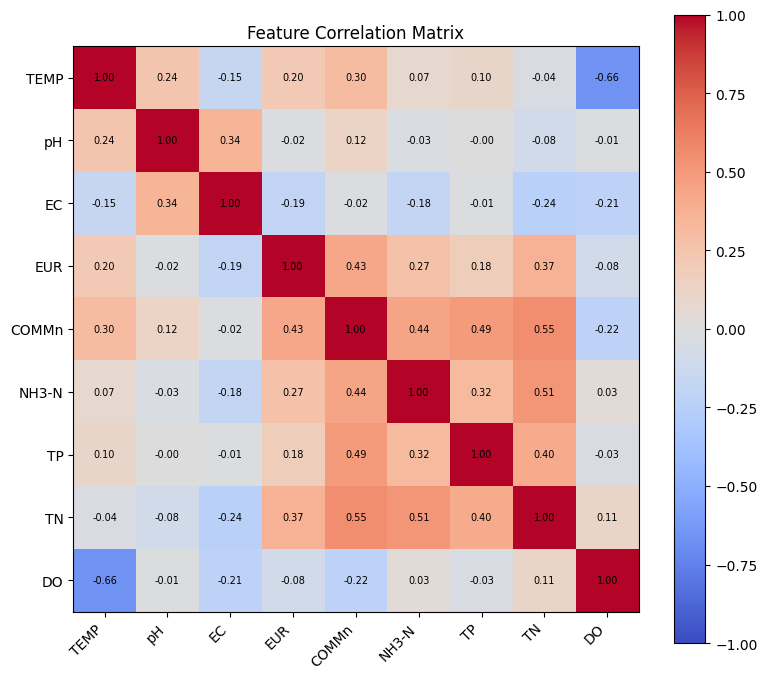

In [8]:
corr = raw_df[FEATURE_COLS].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURE_COLS))); ax.set_xticklabels(FEATURE_COLS, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURE_COLS))); ax.set_yticklabels(FEATURE_COLS)
for i in range(len(FEATURE_COLS)):
    for j in range(len(FEATURE_COLS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

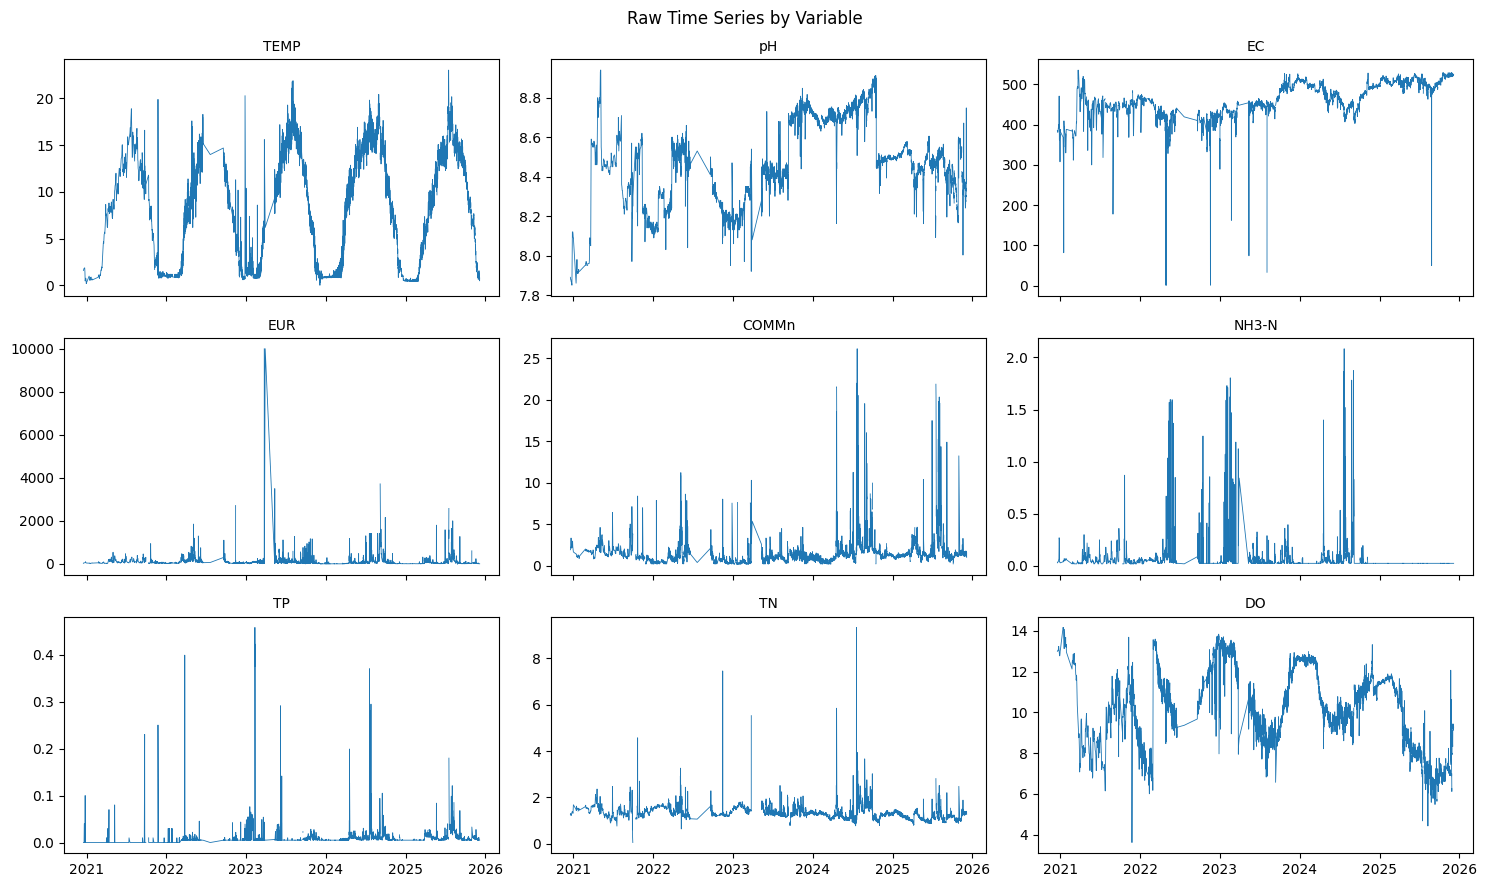

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 9), sharex=True)
for ax, col in zip(axes.ravel(), FEATURE_COLS):
    ax.plot(raw_df["time"], raw_df[col], linewidth=0.6)
    ax.set_title(col, fontsize=10)
plt.suptitle("Raw Time Series by Variable")
plt.tight_layout()
plt.show()

In [10]:
def load_and_clean(csv_path, max_interp_steps=12):
    df = pd.read_csv(csv_path)
    df["time"] = pd.to_datetime(df["time"])
    df = df.sort_values("time").drop_duplicates(subset="time")
    df = df.set_index("time")[FEATURE_COLS]

    full_index = pd.date_range(df.index.min(), df.index.max(), freq="4h")
    df = df.reindex(full_index)
    df.index.name = "time"

    df = df.interpolate(method="linear", limit=max_interp_steps, limit_direction="both")
    df = df.ffill().bfill()
    return df

df = load_and_clean(CSV_PATH)
print("Clean shape:", df.shape)
print("Remaining NaNs:\n", df.isna().sum())
df.head()

Clean shape: (10884, 9)
Remaining NaNs:
 TEMP     0
pH       0
EC       0
EUR      0
COMMn    0
NH3-N    0
TP       0
TN       0
DO       0
dtype: int64


,TEMP,pH,EC,EUR,COMMn,NH3-N,TP,TN,DO
time,,,,,,,,,
2020-12-17 20:00:00,1.600000,7.890000,385.25,23.250000,1.950000,0.03,0.0,1.280000,13.000000
2020-12-18 00:00:00,1.616667,7.888333,384.93,26.541667,2.001667,0.03,0.0,1.283333,13.001667
2020-12-18 04:00:00,1.633333,7.886667,384.61,29.833333,2.053333,0.03,0.0,1.286667,13.003333
2020-12-18 08:00:00,1.650000,7.885000,384.29,33.125000,2.105000,0.03,0.0,1.290000,13.005000
2020-12-18 12:00:00,1.666667,7.883333,383.97,36.416667,2.156667,0.03,0.0,1.293333,13.006667


In [11]:
def chronological_split(df, train_frac=0.7, val_frac=0.15):
    n = len(df)
    n_train = int(n * train_frac)
    n_val = int(n * val_frac)
    train = df.iloc[:n_train]
    val = df.iloc[n_train:n_train + n_val]
    test = df.iloc[n_train + n_val:]
    return train, val, test

train_df, val_df, test_df = chronological_split(df)
print("train/val/test sizes:", len(train_df), len(val_df), len(test_df))

train/val/test sizes: 7618 1632 1634


In [13]:
scaler = StandardScaler()
scaler.fit(train_df[FEATURE_COLS].values)

def scale_df(d):
    return scaler.transform(d[FEATURE_COLS].values)

def inverse_transform_do(scaled_do):
    mean = scaler.mean_[-1]  # DO is the last column
    std = scaler.scale_[-1]
    return scaled_do * std + mean

In [14]:
LOOKBACK = 24
HORIZON = 6
TARGET_IDX = -1  # DO is last column in FEATURE_COLS

def make_windows(scaled_array, lookback=LOOKBACK, horizon=HORIZON, target_idx=TARGET_IDX):
    T = scaled_array.shape[0]
    n_samples = T - lookback - horizon + 1
    if n_samples <= 0:
        raise ValueError("Not enough timesteps for the requested lookback/horizon.")
    n_features = scaled_array.shape[1]
    X = np.zeros((n_samples, lookback, n_features), dtype=np.float32)
    y = np.zeros((n_samples, horizon), dtype=np.float32)
    for i in range(n_samples):
        X[i] = scaled_array[i:i + lookback]
        y[i] = scaled_array[i + lookback:i + lookback + horizon, target_idx]
    return X, y

X_train, y_train = make_windows(scale_df(train_df))
X_val,   y_val   = make_windows(scale_df(val_df))
X_test,  y_test  = make_windows(scale_df(test_df))

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  "y_test: ", y_test.shape)

X_train: (7589, 24, 9) y_train: (7589, 6)
X_val:   (1603, 24, 9) y_val:   (1603, 6)
X_test:  (1605, 24, 9) y_test:  (1605, 6)


In [15]:
from torch.utils.data import Dataset, DataLoader

class DOWindowDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 32

train_loader = DataLoader(DOWindowDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(DOWindowDataset(X_val,   y_val),   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(DOWindowDataset(X_test,  y_test),  batch_size=BATCH_SIZE, shuffle=False)

xb, yb = next(iter(train_loader))
print("batch X:", xb.shape, "batch y:", yb.shape)

batch X: torch.Size([32, 24, 9]) batch y: torch.Size([32, 6])


In [16]:
PATCH_LEN = 4
STRIDE = 2

def make_patches(x, patch_len=PATCH_LEN, stride=STRIDE):
    """x: (batch, lookback, n_features) -> (batch, num_patches, patch_len*n_features)"""
    batch, lookback, n_features = x.shape
    patches = x.unfold(dimension=1, size=patch_len, step=stride)   # (batch, num_patches, n_features, patch_len)
    patches = patches.permute(0, 1, 3, 2)                          # (batch, num_patches, patch_len, n_features)
    patches = patches.reshape(batch, patches.shape[1], patch_len * n_features)
    return patches

def num_patches_for(lookback, patch_len=PATCH_LEN, stride=STRIDE):
    return (lookback - patch_len) // stride + 1

NUM_PATCHES = num_patches_for(LOOKBACK)
print("num_patches:", NUM_PATCHES)

# sanity check
_test_patches = make_patches(torch.from_numpy(X_train[:2]))
print("patches shape:", _test_patches.shape)  # (2, 11, 36)

num_patches: 11
patches shape: torch.Size([2, 11, 36])


In [17]:
USE_LARGE_MODEL = True  # official recommended config; set False for a lighter/faster CPU-friendly model

if USE_LARGE_MODEL:
    D_MODEL = 512
    D_FF = 2048
else:
    D_MODEL = 256
    D_FF = 1024

print(f"D_MODEL={D_MODEL}, D_FF={D_FF}")

class PatchEmbedding(nn.Module):
    def __init__(self, patch_len, n_features, d_model):
        super().__init__()
        self.proj = nn.Linear(patch_len * n_features, d_model)

    def forward(self, patches):
        return self.proj(patches)  # (batch, num_patches, d_model)

D_MODEL=512, D_FF=2048


In [18]:
class LearnablePositionalEncoding(nn.Module):
    def __init__(self, num_patches, d_model):
        super().__init__()
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches, d_model))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        return x + self.pos_embed

In [19]:
N_HEADS = 8
NUM_LAYERS = 3
DROPOUT = 0.05  # official-recommended value for this dataset (lighter than the 0.2-0.3 used in some PatchTST experiments)

def build_transformer_encoder(d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_LAYERS,
                               d_ff=D_FF, dropout=DROPOUT):
    encoder_layer = nn.TransformerEncoderLayer(
        d_model=d_model,
        nhead=n_heads,
        dim_feedforward=d_ff,
        dropout=dropout,
        activation="gelu",
        batch_first=True,
        norm_first=True,   # Pre-LN: LayerNorm -> Attention/FF -> Residual add
    )
    return nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

In [20]:
HEAD_DROPOUT = 0.1

class PatchTST(nn.Module):
    def __init__(self, n_features, lookback=LOOKBACK, horizon=HORIZON,
                 patch_len=PATCH_LEN, stride=STRIDE, d_model=D_MODEL,
                 n_heads=N_HEADS, num_layers=NUM_LAYERS, d_ff=D_FF,
                 dropout=DROPOUT, head_dropout=HEAD_DROPOUT):
        super().__init__()
        self.patch_len = patch_len
        self.stride = stride
        self.num_patches = num_patches_for(lookback, patch_len, stride)

        self.patch_embed = PatchEmbedding(patch_len, n_features, d_model)
        self.pos_encoding = LearnablePositionalEncoding(self.num_patches, d_model)
        self.input_dropout = nn.Dropout(dropout)
        self.encoder = build_transformer_encoder(d_model, n_heads, num_layers, d_ff, dropout)

        self.flatten = nn.Flatten(start_dim=1)
        self.head_dropout = nn.Dropout(head_dropout)
        self.head = nn.Linear(self.num_patches * d_model, horizon)

    def forward(self, x):
        # x: (batch, lookback, n_features)
        patches = make_patches(x, self.patch_len, self.stride)
        z = self.patch_embed(patches)
        z = self.pos_encoding(z)
        z = self.input_dropout(z)
        z = self.encoder(z)
        z = self.flatten(z)
        z = self.head_dropout(z)
        return self.head(z)


model = PatchTST(n_features=len(FEATURE_COLS)).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"num_patches = {model.num_patches} | trainable params = {n_params:,}")

# sanity check forward pass
_xb = torch.randn(BATCH_SIZE, LOOKBACK, len(FEATURE_COLS)).to(DEVICE)
_out = model(_xb)
print("output shape:", _out.shape)  # (32, 6)

num_patches = 11 | trainable params = 9,515,526
output shape: torch.Size([32, 6])


In [21]:
criterion = nn.MSELoss()

In [22]:
LR = 1e-3
optimizer = optim.Adam(model.parameters(), lr=LR)

In [23]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

In [24]:
EPOCHS = 100
PATIENCE = 10

best_val_loss = float("inf")
best_state = None
epochs_no_improve = 0

In [25]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, n_batches = 0.0, 0
    with torch.set_grad_enabled(is_train):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb)
            loss = criterion(pred, yb)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item()
            n_batches += 1

    return total_loss / n_batches


history = {"train_loss": [], "val_loss": [], "lr": []}
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(model, train_loader, criterion, optimizer)
    val_loss = run_epoch(model, val_loader, criterion, None)
    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["lr"].append(current_lr)
    print(f"Epoch {epoch:3d}/{EPOCHS} | train_loss={train_loss:.5f} | val_loss={val_loss:.5f} | lr={current_lr:.2e}")

    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping triggered at epoch {epoch} (patience={PATIENCE}).")
            break

train_time = time.time() - t0
print(f"Total training time: {train_time:.1f}s")

Epoch   1/100 | train_loss=0.91905 | val_loss=0.10385 | lr=1.00e-03
Epoch   2/100 | train_loss=0.11116 | val_loss=0.06642 | lr=1.00e-03
Epoch   3/100 | train_loss=0.08785 | val_loss=0.09303 | lr=1.00e-03
Epoch   4/100 | train_loss=0.07749 | val_loss=0.06553 | lr=1.00e-03
Epoch   5/100 | train_loss=0.07528 | val_loss=0.05893 | lr=1.00e-03
Epoch   6/100 | train_loss=0.06741 | val_loss=0.05779 | lr=1.00e-03
Epoch   7/100 | train_loss=0.06305 | val_loss=0.04892 | lr=1.00e-03
Epoch   8/100 | train_loss=0.06087 | val_loss=0.04991 | lr=1.00e-03
Epoch   9/100 | train_loss=0.06959 | val_loss=0.11571 | lr=1.00e-03
Epoch  10/100 | train_loss=0.06894 | val_loss=0.16898 | lr=1.00e-03
Epoch  11/100 | train_loss=0.07618 | val_loss=0.10136 | lr=5.00e-04
Epoch  12/100 | train_loss=0.05980 | val_loss=0.03929 | lr=5.00e-04
Epoch  13/100 | train_loss=0.04457 | val_loss=0.13759 | lr=5.00e-04
Epoch  14/100 | train_loss=0.04469 | val_loss=0.07736 | lr=5.00e-04
Epoch  15/100 | train_loss=0.04213 | val_loss=0.

In [26]:
model.load_state_dict(best_state)
torch.save(best_state, "best_patchtst_model.pt")
print("Best val loss:", best_val_loss)
print("Saved to best_patchtst_model.pt")

Best val loss: 0.03404304571906287
Saved to best_patchtst_model.pt


In [27]:
model.eval()
preds, actuals = [], []

inf_time_ms = 0.0
with torch.no_grad():
    for i, (xb, yb) in enumerate(test_loader):
        xb = xb.to(DEVICE)
        if i == 0:
            _t0 = time.time()
            _ = model(xb)
            inf_time_ms = (time.time() - _t0) * 1000
        pred = model(xb).cpu().numpy()
        preds.append(pred)
        actuals.append(yb.numpy())

preds = np.concatenate(preds, axis=0)
actuals = np.concatenate(actuals, axis=0)

preds_orig = inverse_transform_do(preds)
actuals_orig = inverse_transform_do(actuals)

print("preds_orig:", preds_orig.shape, "actuals_orig:", actuals_orig.shape)

preds_orig: (1605, 6) actuals_orig: (1605, 6)


In [28]:
metrics = {}
for h in range(preds_orig.shape[1]):
    a, p = actuals_orig[:, h], preds_orig[:, h]
    rmse = float(np.sqrt(mean_squared_error(a, p)))
    mae = float(mean_absolute_error(a, p))
    mape = float(np.mean(np.abs((a - p) / np.clip(np.abs(a), 1e-6, None))) * 100)
    r2 = float(r2_score(a, p))
    metrics[f"step_{h+1}"] = {"rmse": rmse, "mae": mae, "mape_%": mape, "r2": r2}

a_all, p_all = actuals_orig.ravel(), preds_orig.ravel()
metrics["overall"] = {
    "rmse": float(np.sqrt(mean_squared_error(a_all, p_all))),
    "mae": float(mean_absolute_error(a_all, p_all)),
    "mape_%": float(np.mean(np.abs((a_all - p_all) / np.clip(np.abs(a_all), 1e-6, None))) * 100),
    "r2": float(r2_score(a_all, p_all)),
}
metrics["_meta"] = {
    "train_time_sec": round(train_time, 2),
    "inference_time_ms_per_batch": round(inf_time_ms, 3),
    "num_params": int(sum(p.numel() for p in model.parameters())),
    "epochs_run": len(history["train_loss"]),
}

print(json.dumps(metrics, indent=2))

{
  "step_1": {
    "rmse": 0.40535807557068,
    "mae": 0.28252149569860124,
    "mape_%": 3.8355574799690513,
    "r2": 0.9115003538930804
  },
  "step_2": {
    "rmse": 0.46600647691055364,
    "mae": 0.33038006042094853,
    "mape_%": 4.466293414022066,
    "r2": 0.8827309966268216
  },
  "step_3": {
    "rmse": 0.5268237441026398,
    "mae": 0.3775749066955249,
    "mape_%": 5.166530533402787,
    "r2": 0.8497559629136782
  },
  "step_4": {
    "rmse": 0.5655894543471865,
    "mae": 0.40691626570224226,
    "mape_%": 5.571512306822032,
    "r2": 0.8264296174520187
  },
  "step_5": {
    "rmse": 0.6268202540575533,
    "mae": 0.4670988488395393,
    "mape_%": 6.4354758923033595,
    "r2": 0.786354444721537
  },
  "step_6": {
    "rmse": 0.6862343862435122,
    "mae": 0.5187891045717816,
    "mape_%": 7.163017197452282,
    "r2": 0.7433831077672106
  },
  "overall": {
    "rmse": 0.5541860635099324,
    "mae": 0.39721344698810623,
    "mape_%": 5.439731137328597,
    "r2": 0.8335825

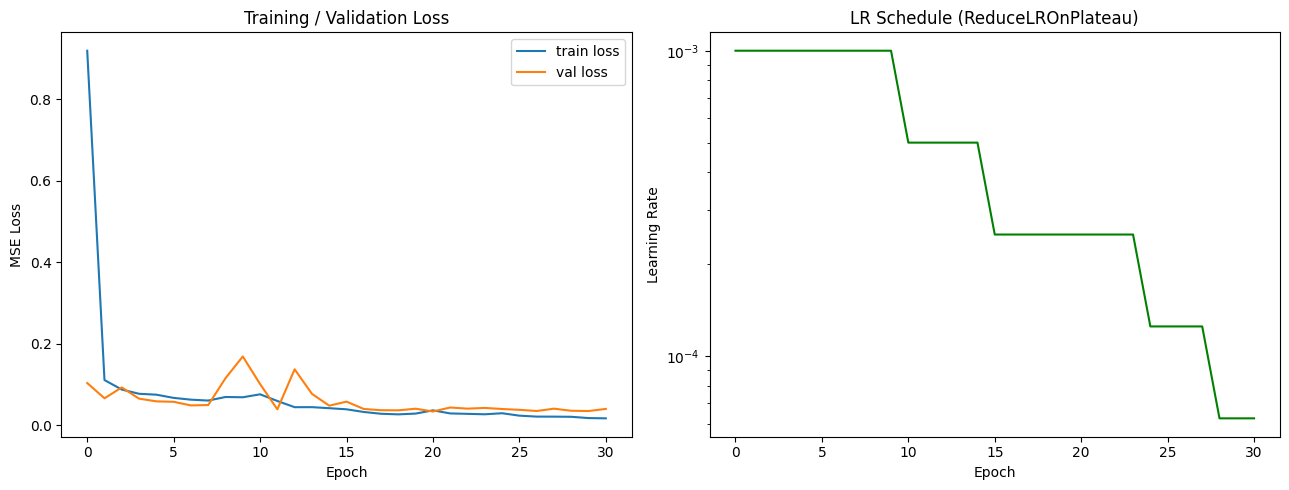

In [29]:
# --- Loss curve + LR schedule ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(history["train_loss"], label="train loss")
axes[0].plot(history["val_loss"], label="val loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE Loss")
axes[0].set_title("Training / Validation Loss"); axes[0].legend()

axes[1].plot(history["lr"], color="green")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Learning Rate")
axes[1].set_title("LR Schedule (ReduceLROnPlateau)"); axes[1].set_yscale("log")

plt.tight_layout()
plt.savefig("training_curve.png", dpi=150)
plt.show()

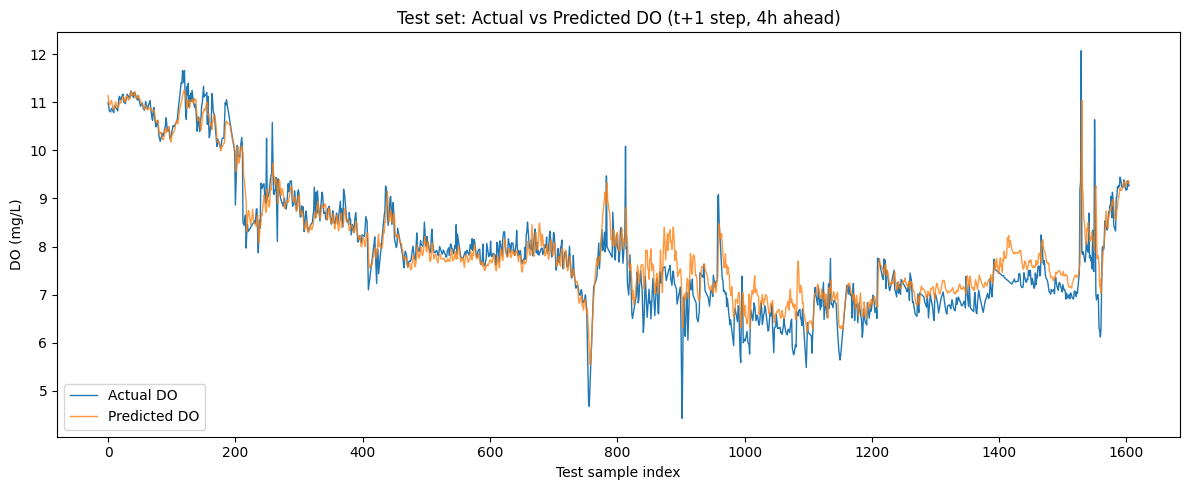

In [30]:
# --- Prediction vs Actual ---
STEP_TO_PLOT = 0  # 0 = t+1 (4h ahead) ... 5 = t+6 (24h ahead)

plt.figure(figsize=(12, 5))
plt.plot(actuals_orig[:, STEP_TO_PLOT], label="Actual DO", linewidth=1)
plt.plot(preds_orig[:, STEP_TO_PLOT], label="Predicted DO", linewidth=1, alpha=0.8)
plt.xlabel("Test sample index"); plt.ylabel("DO (mg/L)")
plt.title(f"Test set: Actual vs Predicted DO (t+{STEP_TO_PLOT+1} step, {(STEP_TO_PLOT+1)*4}h ahead)")
plt.legend()
plt.tight_layout()
plt.savefig("test_predictions.png", dpi=150)
plt.show()

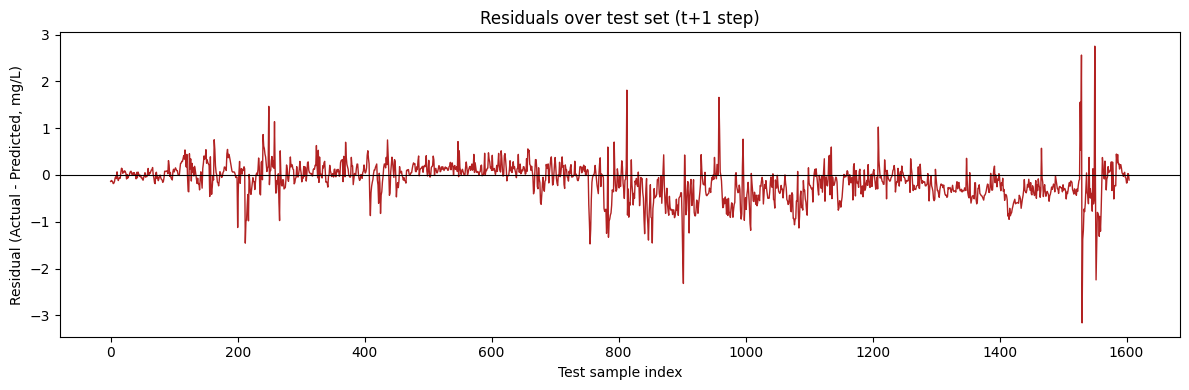

In [31]:
# --- Residuals ---
residuals = actuals_orig[:, STEP_TO_PLOT] - preds_orig[:, STEP_TO_PLOT]
plt.figure(figsize=(12, 4))
plt.plot(residuals, linewidth=1, color="firebrick")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Test sample index"); plt.ylabel("Residual (Actual - Predicted, mg/L)")
plt.title(f"Residuals over test set (t+{STEP_TO_PLOT+1} step)")
plt.tight_layout()
plt.savefig("residual_plot.png", dpi=150)
plt.show()

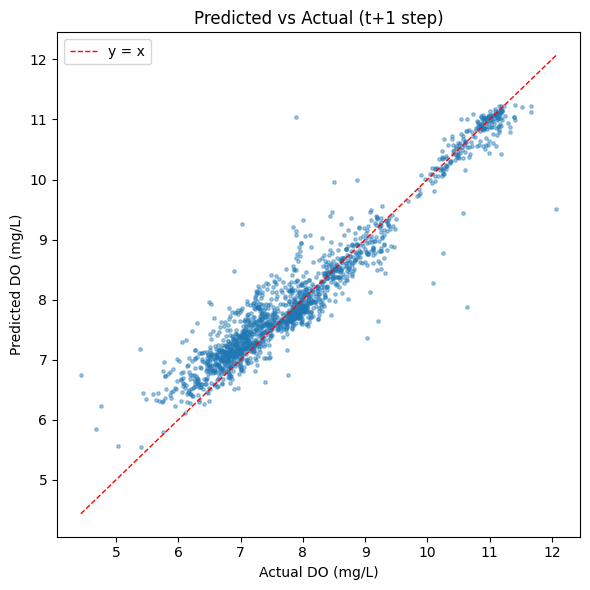

In [32]:
# --- Scatter: Predicted vs Actual ---
a, p = actuals_orig[:, STEP_TO_PLOT], preds_orig[:, STEP_TO_PLOT]
lims = [min(a.min(), p.min()), max(a.max(), p.max())]

plt.figure(figsize=(6, 6))
plt.scatter(a, p, s=6, alpha=0.4)
plt.plot(lims, lims, "r--", linewidth=1, label="y = x")
plt.xlabel("Actual DO (mg/L)"); plt.ylabel("Predicted DO (mg/L)")
plt.title(f"Predicted vs Actual (t+{STEP_TO_PLOT+1} step)")
plt.legend()
plt.tight_layout()
plt.savefig("scatter_plot.png", dpi=150)
plt.show()

In [33]:
with open("metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

cols = {}
for h in range(preds_orig.shape[1]):
    cols[f"actual_t+{h+1}"] = actuals_orig[:, h]
    cols[f"pred_t+{h+1}"] = preds_orig[:, h]
pd.DataFrame(cols).to_csv("predictions.csv", index=False)

print("Saved: metrics.json, predictions.csv, best_patchtst_model.pt")
print("Saved plots: training_curve.png, test_predictions.png, residual_plot.png, scatter_plot.png")

Saved: metrics.json, predictions.csv, best_patchtst_model.pt
Saved plots: training_curve.png, test_predictions.png, residual_plot.png, scatter_plot.png


In [ ]:
from google.colab import files as colab_files

for fname in ["best_patchtst_model.pt", "metrics.json", "predictions.csv",
              "training_curve.png", "test_predictions.png", "residual_plot.png", "scatter_plot.png"]:
    colab_files.download(fname)